# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# 🛒 E-Commerce Sales Analytics: Revenue, Customers & Insights

## 📌 Project Overview

This project analyzes e-commerce sales data to uncover patterns in revenue, customer behavior, product performance, payment preferences, and delivery performance.

### Objectives

- Analyze overall sales and revenue performance
- Identify high-performing product categories
- Understand customer and regional behavior
- Analyze payment methods and discounts
- Examine delivery performance and customer ratings
- Generate actionable business insights

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [110]:
df = pd.read_csv("/kaggle/input/datasets/arshanalytica/e-commerce-sales-analytics-dataset/ecommerce_sales_analytics_5000.csv")

In [111]:
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [112]:
df.shape

(5000, 12)

In [113]:
df.info

<bound method DataFrame.info of       order_id order_date  customer_id product_category region  quantity  \
0        10001   1/1/2022         1102           Beauty  South         7   
1        10002   1/2/2022         1435         Clothing  South         7   
2        10003   1/3/2022         1860           Beauty   East         3   
3        10004   1/4/2022         1270      Electronics   West         5   
4        10005   1/5/2022         1106         Clothing   West         5   
...        ...        ...          ...              ...    ...       ...   
4995     14996   9/5/2035         1289         Clothing   West         2   
4996     14997   9/6/2035         1294           Beauty  North         3   
4997     14998   9/7/2035         1450           Beauty   West         3   
4998     14999   9/8/2035         1903      Electronics  South         4   
4999     15000   9/9/2035         1214             Home   East         7   

      unit_price  discount payment_method  delivery_day

In [114]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

In [115]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [116]:
df.duplicated().sum()

np.int64(0)

In [117]:
df["order_id"].duplicated().sum()

np.int64(0)

In [118]:
df.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [119]:
df.nunique()

order_id            5000
order_date          5000
customer_id          989
product_category       4
region                 4
quantity               7
unit_price          4788
discount              36
payment_method         3
delivery_days         11
customer_rating       41
revenue             4940
dtype: int64

In [120]:
df.dtypes

order_id              int64
order_date           object
customer_id           int64
product_category     object
region               object
quantity              int64
unit_price          float64
discount            float64
payment_method       object
delivery_days         int64
customer_rating     float64
revenue             float64
dtype: object

In [121]:
df["order_date"].head()

0    1/1/2022
1    1/2/2022
2    1/3/2022
3    1/4/2022
4    1/5/2022
Name: order_date, dtype: object

In [122]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [123]:
df.dtypes

order_id                     int64
order_date          datetime64[ns]
customer_id                  int64
product_category            object
region                      object
quantity                     int64
unit_price                 float64
discount                   float64
payment_method              object
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object

In [124]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()

In [125]:
df[["order_date", "year", "month", "month_name"]].head()

,order_date,year,month,month_name
0,2022-01-01,2022,1,January
1,2022-01-02,2022,1,January
2,2022-01-03,2022,1,January
3,2022-01-04,2022,1,January
4,2022-01-05,2022,1,January


In [126]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "ecommerce_sales_analytics_5000.csv":
            print(os.path.join(root, file))

/kaggle/input/datasets/arshanalytica/e-commerce-sales-analytics-dataset/ecommerce_sales_analytics_5000.csv


In [127]:
import pandas as pd
import glob

file_path = glob.glob("/kaggle/input/**/ecommerce_sales_analytics_5000.csv", recursive=True)[0]

df = pd.read_csv(file_path)

df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [128]:
# Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Create date-based columns
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()

# Check the result
df[["order_date", "year", "month", "month_name"]].head()

,order_date,year,month,month_name
0,2022-01-01,2022,1,January
1,2022-01-02,2022,1,January
2,2022-01-03,2022,1,January
3,2022-01-04,2022,1,January
4,2022-01-05,2022,1,January


In [129]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          5000 non-null   int64         
 1   order_date        5000 non-null   datetime64[ns]
 2   customer_id       5000 non-null   int64         
 3   product_category  5000 non-null   object        
 4   region            5000 non-null   object        
 5   quantity          5000 non-null   int64         
 6   unit_price        5000 non-null   float64       
 7   discount          5000 non-null   float64       
 8   payment_method    5000 non-null   object        
 9   delivery_days     5000 non-null   int64         
 10  customer_rating   5000 non-null   float64       
 11  revenue           5000 non-null   float64       
 12  year              5000 non-null   int32         
 13  month             5000 non-null   int32         
 14  month_name        5000 n

In [130]:
df.describe()

,order_id,order_date,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue,year,month
count,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,2028-11-04 12:00:00,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148,2028.352800,6.430600
min,10001.000000,2022-01-01 00:00:00,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000,2022.000000,1.000000
25%,11250.750000,2025-06-03 18:00:00,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500,2025.000000,3.000000
50%,12500.500000,2028-11-04 12:00:00,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000,2028.000000,6.000000
75%,13750.250000,2032-04-07 06:00:00,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000,2032.000000,9.000000
max,15000.000000,2035-09-09 00:00:00,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000,2035.000000,12.000000
std,1443.520003,NaN,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219,3.954827,3.427584


In [131]:
df.describe(include="object")

,product_category,region,payment_method,month_name
count,5000,5000,5000,5000
unique,4,4,3,12
top,Electronics,West,Card,January
freq,1777,1289,2270,434


In [132]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
year                0
month               0
month_name          0
dtype: int64

In [133]:
df.duplicated().sum()

np.int64(0)

In [134]:
# Overall sales performance

total_revenue = df["revenue"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_quantity = df["quantity"].sum()
average_order_value = total_revenue / total_orders

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 5109775.74
Total Orders: 5000
Total Customers: 989
Total Quantity Sold: 20224
Average Order Value: 1021.96


In [135]:
yearly_revenue = df.groupby("year")["revenue"].sum().reset_index()

yearly_revenue

,year,revenue
0,2022,371824.30
1,2023,365915.79
2,2024,363209.13
3,2025,349802.33
4,2026,386369.69
5,2027,386151.91
6,2028,376844.80
7,2029,359239.24
8,2030,387884.46
9,2031,365250.83


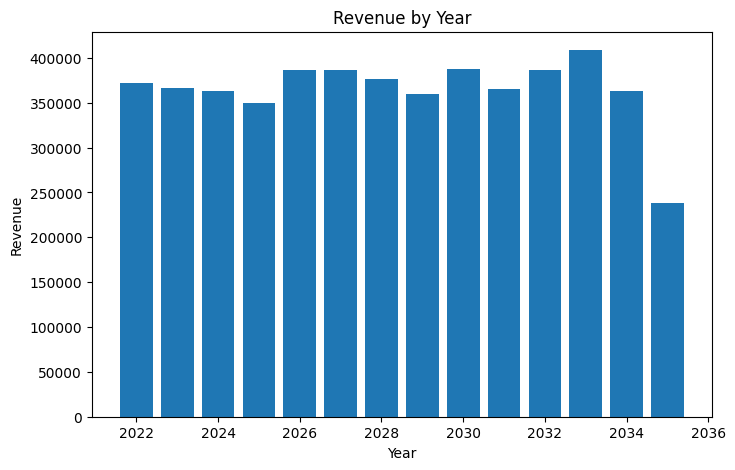

In [136]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(yearly_revenue["year"], yearly_revenue["revenue"])

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")

plt.show()

In [137]:
monthly_revenue = (
    df.groupby(["year", "month", "month_name"])["revenue"]
      .sum()
      .reset_index()
      .sort_values(["year", "month"])
)

monthly_revenue

,year,month,month_name,revenue
0,2022,1,January,35624.89
1,2022,2,February,29908.89
2,2022,3,March,30309.28
3,2022,4,April,30781.96
4,2022,5,May,41629.24
...,...,...,...,...
160,2035,5,May,33393.87
161,2035,6,June,25205.26
162,2035,7,July,23944.48
163,2035,8,August,29354.74


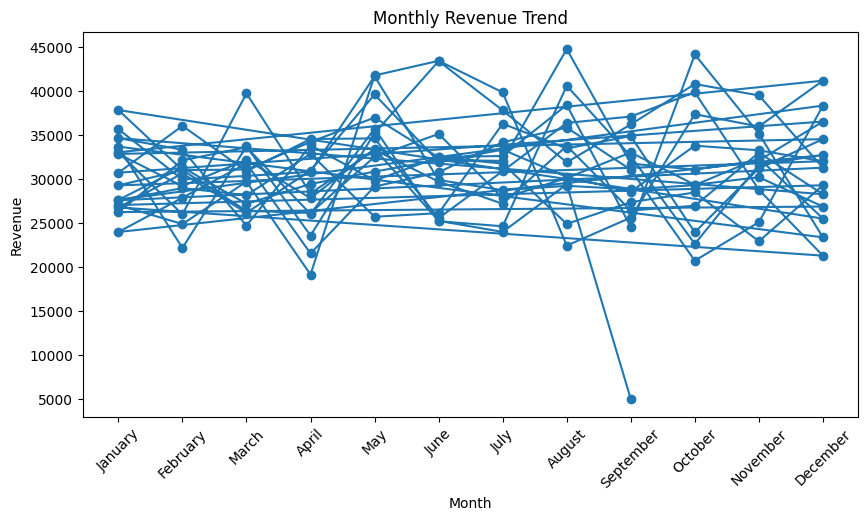

In [138]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue["month_name"],
    monthly_revenue["revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

In [139]:
category_revenue = (
    df.groupby("product_category")["revenue"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

category_revenue

,product_category,revenue
0,Electronics,1829899.22
1,Clothing,1531931.72
2,Home,982083.92
3,Beauty,765860.88


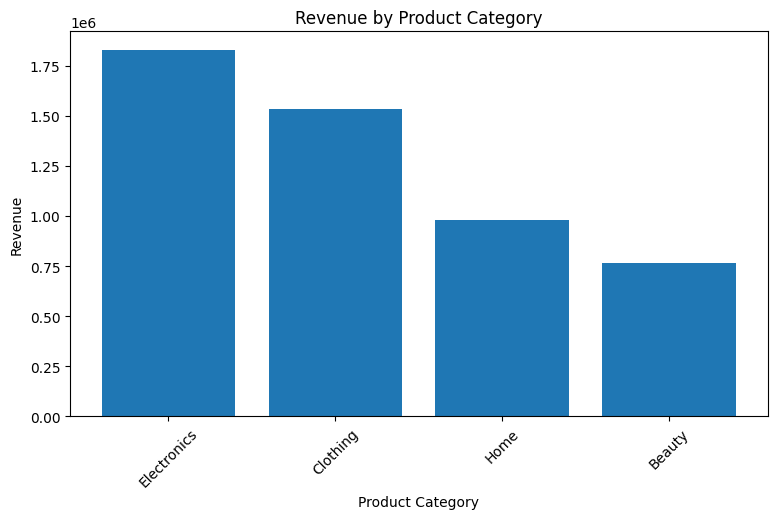

In [140]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_revenue["product_category"],
    category_revenue["revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

In [141]:
category_quantity = (
    df.groupby("product_category")["quantity"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

category_quantity

,product_category,quantity
0,Electronics,7109
1,Clothing,6171
2,Home,3949
3,Beauty,2995


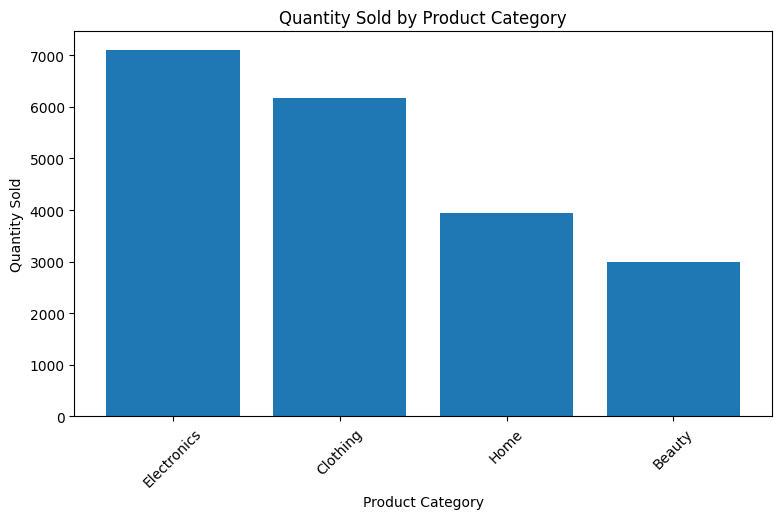

In [142]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_quantity["product_category"],
    category_quantity["quantity"]
)

plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)

plt.show()

In [143]:
region_revenue = (
    df.groupby("region")["revenue"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

region_revenue

,region,revenue
0,West,1345582.16
1,North,1281508.45
2,South,1246640.90
3,East,1236044.23


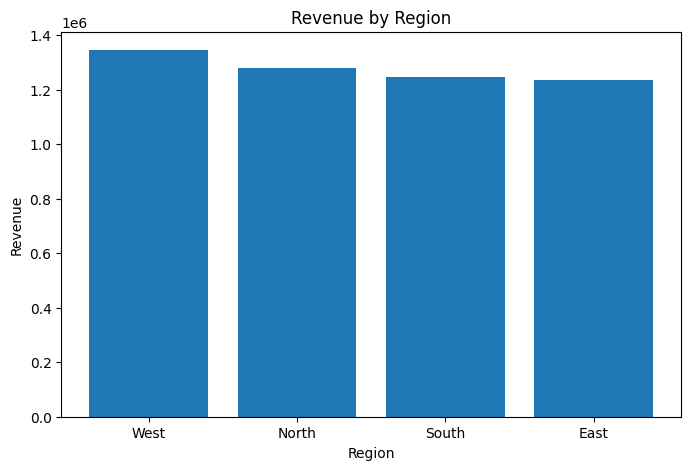

In [144]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_revenue["region"],
    region_revenue["revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.show()

In [145]:
region_orders = (
    df.groupby("region")["order_id"]
      .nunique()
      .sort_values(ascending=False)
      .reset_index()
)

region_orders

,region,order_id
0,West,1289
1,North,1276
2,East,1227
3,South,1208


In [146]:
payment_analysis = (
    df.groupby("payment_method")
      .agg(
          orders=("order_id", "nunique"),
          revenue=("revenue", "sum")
      )
      .sort_values("revenue", ascending=False)
      .reset_index()
)

payment_analysis

,payment_method,orders,revenue
0,Card,2270,2366248.20
1,COD,1774,1788408.44
2,Wallet,956,955119.10


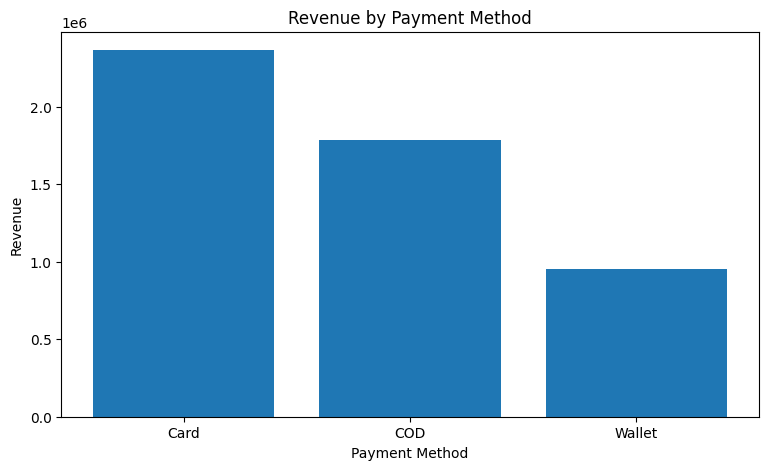

In [147]:
plt.figure(figsize=(9, 5))

plt.bar(
    payment_analysis["payment_method"],
    payment_analysis["revenue"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")

plt.show()

In [148]:
customer_revenue = (
    df.groupby("customer_id")["revenue"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

customer_revenue.head(10)

,customer_id,revenue
0,1663,17680.69
1,1955,16265.15
2,1675,15036.46
3,1276,15023.71
4,1647,14894.97
5,1804,14330.98
6,1193,14151.65
7,1836,14110.78
8,1957,13956.95
9,1735,13146.25


In [149]:
customer_orders = (
    df.groupby("customer_id")["order_id"]
      .nunique()
      .sort_values(ascending=False)
      .reset_index()
)

customer_orders.head(10)

,customer_id,order_id
0,1663,14
1,1957,12
2,1928,12
3,1935,12
4,1112,12
5,1669,12
6,1038,12
7,1098,12
8,1726,11
9,1675,11


In [150]:
discount_analysis = (
    df.groupby("discount")["revenue"]
      .agg(["sum", "mean", "count"])
      .reset_index()
)

discount_analysis

,discount,sum,mean,count
0,0.00,81686.86,1201.277353,68
1,0.01,145677.84,1184.372683,123
2,0.02,201162.79,1257.267438,160
3,0.03,174058.16,1261.291014,138
4,0.04,142728.74,1089.532366,131
5,0.05,158456.80,1237.943750,128
6,0.06,165679.87,1245.713308,133
7,0.07,141067.34,1128.538720,125
8,0.08,160579.10,1130.838732,142
9,0.09,109591.23,978.493125,112


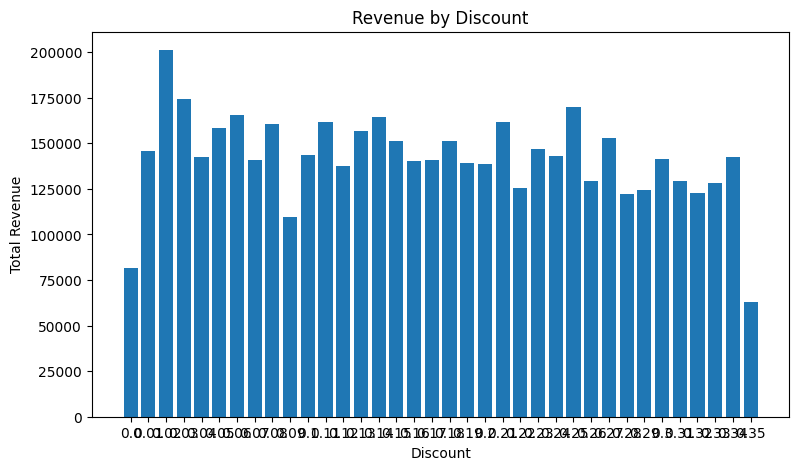

In [151]:
plt.figure(figsize=(9, 5))

plt.bar(
    discount_analysis["discount"].astype(str),
    discount_analysis["sum"]
)

plt.title("Revenue by Discount")
plt.xlabel("Discount")
plt.ylabel("Total Revenue")

plt.show()

In [152]:
delivery_analysis = (
    df.groupby("delivery_days")["revenue"]
      .agg(["sum", "mean", "count"])
      .reset_index()
      .sort_values("delivery_days")
)

delivery_analysis.head(10)

,delivery_days,sum,mean,count
0,1,429131.80,975.299545,440
1,2,434450.54,1024.647500,424
2,3,403409.06,983.924537,410
3,4,515197.31,1086.914156,474
4,5,404718.45,979.947821,413
5,6,505489.47,1050.913659,481
6,7,501727.28,1056.267958,475
7,8,481388.74,1026.415224,469
8,9,469759.40,1032.438242,455
9,10,489609.26,995.140772,492


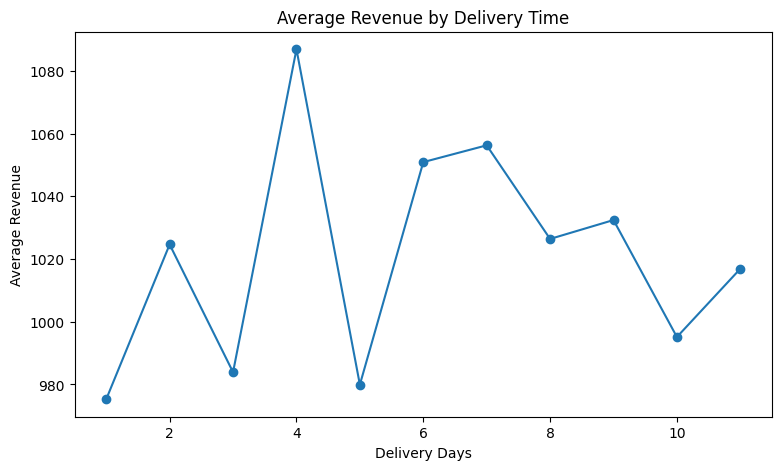

In [153]:
plt.figure(figsize=(9, 5))

plt.plot(
    delivery_analysis["delivery_days"],
    delivery_analysis["mean"],
    marker="o"
)

plt.title("Average Revenue by Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Average Revenue")

plt.show()

In [154]:
rating_analysis = (
    df.groupby("customer_rating")["revenue"]
      .agg(["sum", "mean", "count"])
      .reset_index()
      .sort_values("customer_rating")
)

rating_analysis

,customer_rating,sum,mean,count
0,1.0,78240.73,978.009125,80
1,1.1,121937.49,1007.747851,121
2,1.2,114870.88,965.301513,119
3,1.3,126760.45,1014.083600,125
4,1.4,142847.24,1066.024179,134
5,1.5,144488.89,1120.068915,129
6,1.6,112838.09,924.902377,122
7,1.7,134355.48,939.548811,143
8,1.8,124884.58,983.343150,127
9,1.9,136175.31,1184.133130,115


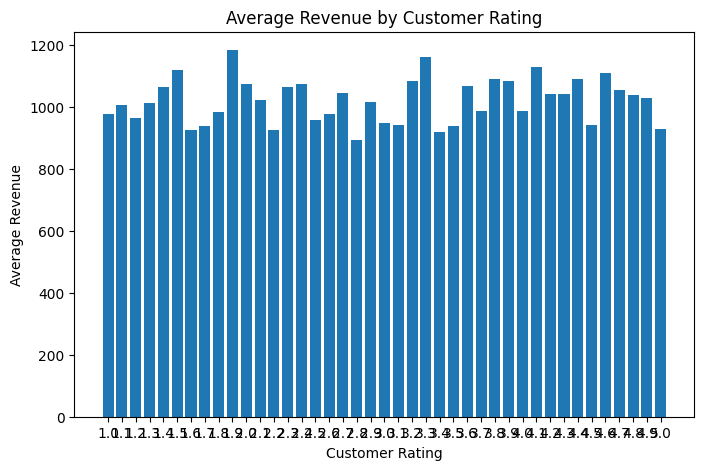

In [155]:
plt.figure(figsize=(8, 5))

plt.bar(
    rating_analysis["customer_rating"].astype(str),
    rating_analysis["mean"]
)

plt.title("Average Revenue by Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Average Revenue")

plt.show()

In [156]:
numeric_columns = [
    "quantity",
    "unit_price",
    "discount",
    "delivery_days",
    "customer_rating",
    "revenue"
]

correlation = df[numeric_columns].corr()

correlation

,quantity,unit_price,discount,delivery_days,customer_rating,revenue
quantity,1.000000,0.001498,-0.004302,-0.008748,0.019168,0.623564
unit_price,0.001498,1.000000,0.013215,0.015623,0.005025,0.678032
discount,-0.004302,0.013215,1.000000,-0.000382,0.012776,-0.139296
delivery_days,-0.008748,0.015623,-0.000382,1.000000,-0.017625,0.005444
customer_rating,0.019168,0.005025,0.012776,-0.017625,1.000000,0.012446
revenue,0.623564,0.678032,-0.139296,0.005444,0.012446,1.000000


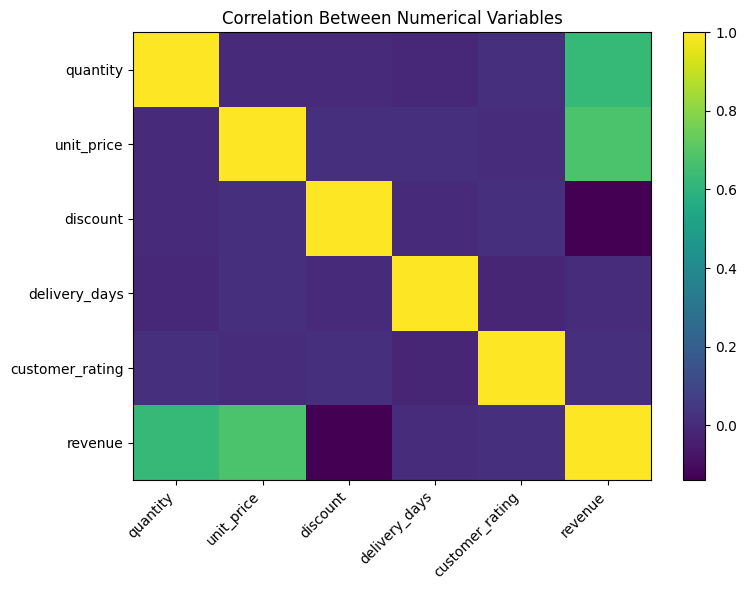

In [157]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, aspect="auto")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between Numerical Variables")
plt.colorbar()

plt.tight_layout()
plt.show()

In [158]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/arshanalytica/e-commerce-sales-analytics-dataset/ecommerce_sales_analytics_5000.csv


In [159]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/kaggle/input/datasets/arshanalytica/e-commerce-sales-analytics-dataset/ecommerce_sales_analytics_5000.csv')

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

   order_id order_date  customer_id product_category region  quantity  \
0     10001   1/1/2022         1102           Beauty  South         7   
1     10002   1/2/2022         1435         Clothing  South         7   
2     10003   1/3/2022         1860           Beauty   East         3   
3     10004   1/4/2022         1270      Electronics   West         5   
4     10005   1/5/2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31            COD              6              2.5   
3      524.47      0.02         Wallet              6              1.6   
4      139.87      0.33         Wallet              4              4.9   

   revenue  
0  1883.20  
1   304.10  
2   644.35  
3  2569.90  
4   468.56  
Dataset shape: (5000, 12)
Columns: ['o

In [160]:
category_revenue = (
    df.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue)

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64


In [161]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (5000, 12)

Column names:
['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue']

First 5 rows:


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [162]:
category_revenue = (
    df.groupby("product_category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(category_revenue)

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

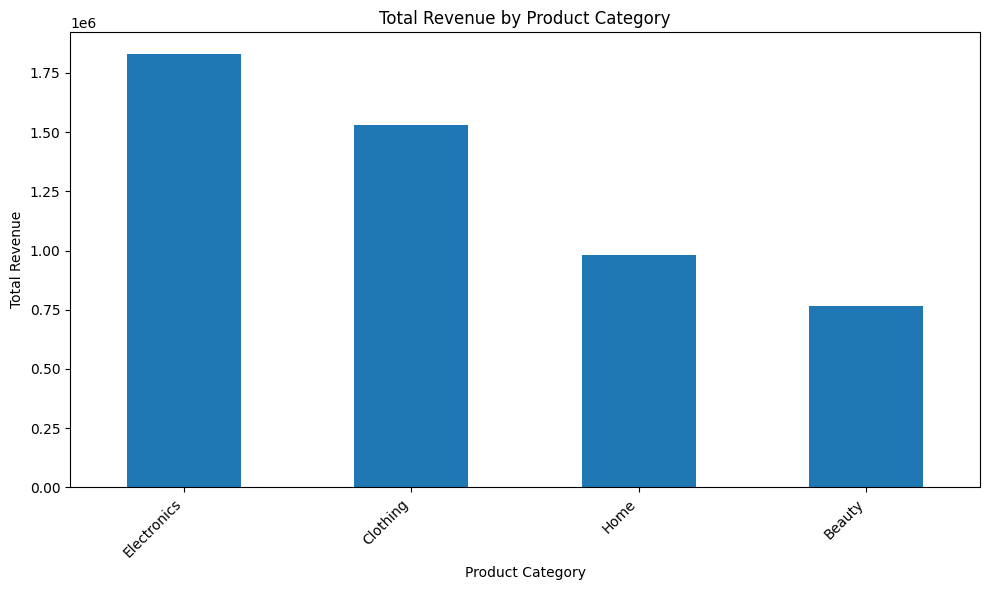

In [163]:
plt.figure(figsize=(10, 6))

category_revenue.plot(kind="bar")

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [164]:
print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue']


In [165]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

monthly_revenue = (
    df.groupby("year_month")["revenue"]
    .sum()
    .sort_index()
)

display(monthly_revenue)

year_month
2022-01    35624.89
2022-02    29908.89
2022-03    30309.28
2022-04    30781.96
2022-05    41629.24
             ...   
2035-05    33393.87
2035-06    25205.26
2035-07    23944.48
2035-08    29354.74
2035-09     4952.23
Name: revenue, Length: 165, dtype: float64

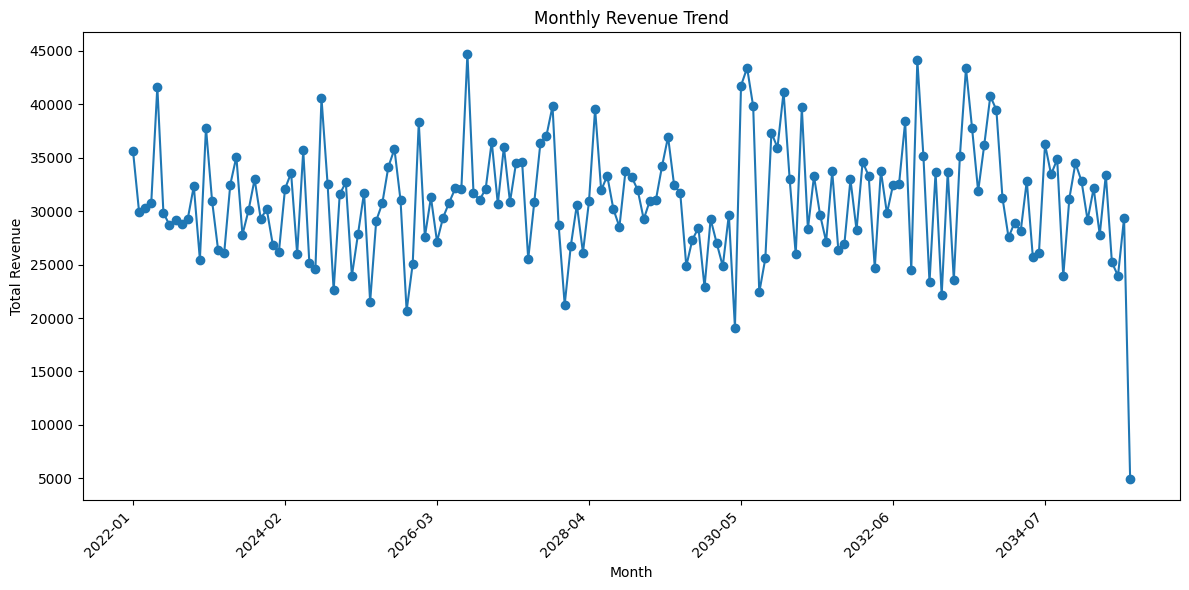

In [166]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [167]:
region_revenue = (
    df.groupby("region")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(region_revenue)

region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64

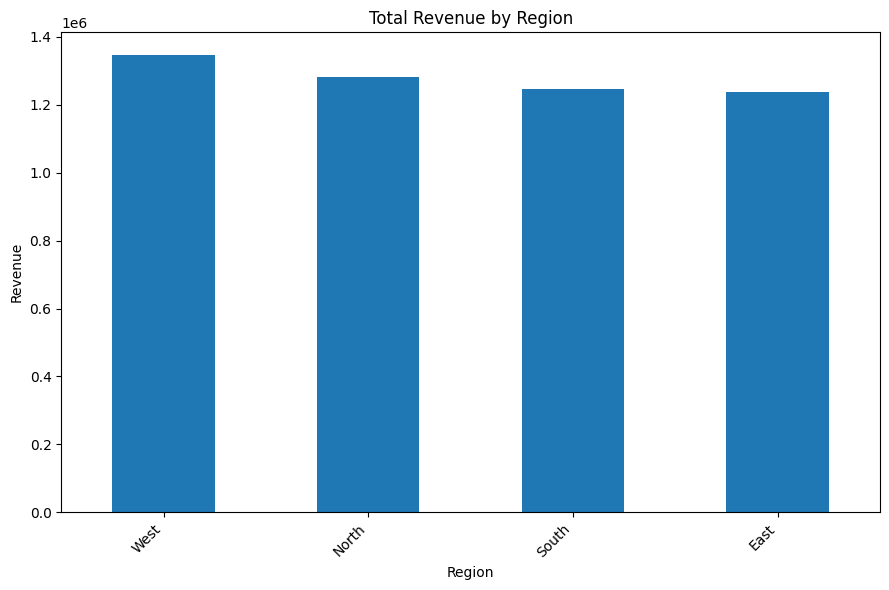

In [168]:
plt.figure(figsize=(9, 6))

region_revenue.plot(kind="bar")

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [169]:
payment_counts = df["payment_method"].value_counts()

display(payment_counts)

payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64

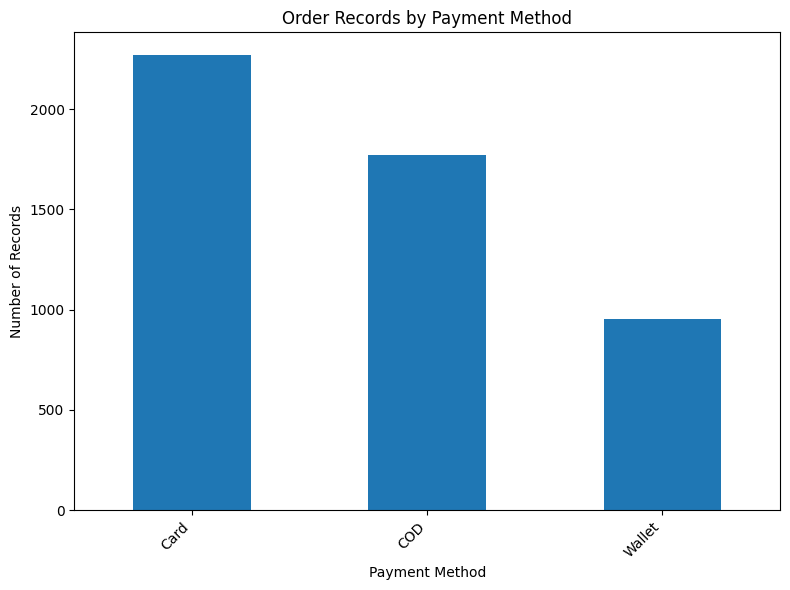

In [170]:
plt.figure(figsize=(8, 6))

payment_counts.plot(kind="bar")

plt.title("Order Records by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [171]:
payment_revenue = (
    df.groupby("payment_method")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(payment_revenue)

payment_method
Card      2366248.20
COD       1788408.44
Wallet     955119.10
Name: revenue, dtype: float64

In [172]:
rating_analysis = (
    df.groupby("delivery_days")
    .agg(
        average_rating=("customer_rating", "mean"),
        number_of_records=("customer_rating", "count")
    )
    .reset_index()
    .sort_values("delivery_days")
)

display(rating_analysis)

,delivery_days,average_rating,number_of_records
0,1,2.988636,440
1,2,2.935849,424
2,3,2.931463,410
3,4,3.071308,474
4,5,3.044310,413
5,6,2.963617,481
6,7,3.024632,475
7,8,2.985501,469
8,9,2.953846,455
9,10,2.924593,492


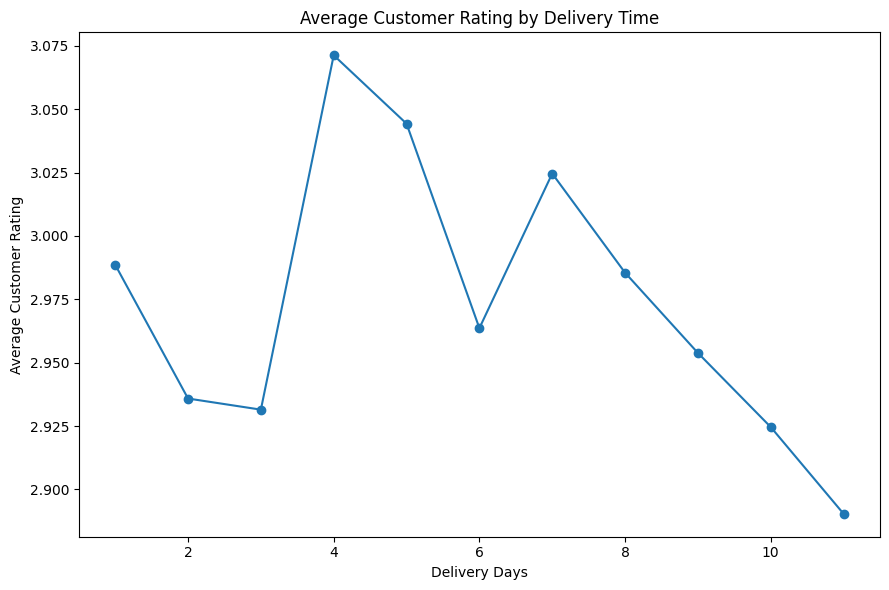

In [173]:
plt.figure(figsize=(9, 6))

plt.plot(
    rating_analysis["delivery_days"],
    rating_analysis["average_rating"],
    marker="o"
)

plt.title("Average Customer Rating by Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Average Customer Rating")

plt.tight_layout()
plt.show()

In [174]:
discount_analysis = (
    df.groupby("discount")
    .agg(
        total_revenue=("revenue", "sum"),
        average_revenue=("revenue", "mean"),
        record_count=("revenue", "count")
    )
    .reset_index()
    .sort_values("discount")
)

display(discount_analysis)

,discount,total_revenue,average_revenue,record_count
0,0.00,81686.86,1201.277353,68
1,0.01,145677.84,1184.372683,123
2,0.02,201162.79,1257.267438,160
3,0.03,174058.16,1261.291014,138
4,0.04,142728.74,1089.532366,131
5,0.05,158456.80,1237.943750,128
6,0.06,165679.87,1245.713308,133
7,0.07,141067.34,1128.538720,125
8,0.08,160579.10,1130.838732,142
9,0.09,109591.23,978.493125,112


In [175]:
# Key Business Performance Indicators

total_revenue = df["revenue"].sum()

total_orders = df["order_id"].nunique()

total_customers = df["customer_id"].nunique()

average_order_value = total_revenue / total_orders if total_orders > 0 else 0

average_rating = df["customer_rating"].mean()

average_delivery_time = df["delivery_days"].mean()

print("========== E-COMMERCE BUSINESS KPIs ==========")

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Average Customer Rating: {average_rating:.2f}")
print(f"Average Delivery Time: {average_delivery_time:.2f} days")

========== E-COMMERCE BUSINESS KPIs ==========
Total Revenue: 5,109,775.74
Total Orders: 5,000
Total Customers: 989
Average Order Value: 1,021.96
Average Customer Rating: 2.97
Average Delivery Time: 6.12 days


In [176]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Average Order Value",
        "Average Customer Rating",
        "Average Delivery Time"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        round(average_order_value, 2),
        round(average_rating, 2),
        round(average_delivery_time, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Revenue,5109775.74
1,Total Orders,5000.00
2,Total Customers,989.00
3,Average Order Value,1021.96
4,Average Customer Rating,2.97
5,Average Delivery Time,6.12


In [177]:
# Analyze customer purchase frequency

customer_orders = (
    df.groupby("customer_id")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

display(customer_orders.head())

,customer_id,total_orders
0,1000,9
1,1001,6
2,1002,4
3,1003,2
4,1004,5


In [178]:
customer_orders["customer_type"] = customer_orders[
    "total_orders"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

customer_type_counts = customer_orders[
    "customer_type"
].value_counts()

display(customer_type_counts)

customer_type
Repeat Customer      950
One-Time Customer     39
Name: count, dtype: int64

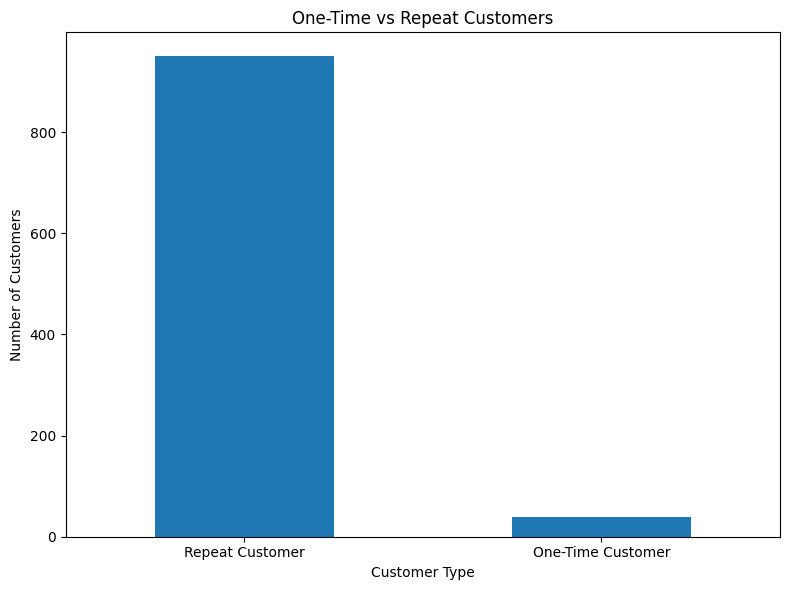

In [179]:
plt.figure(figsize=(8, 6))

customer_type_counts.plot(kind="bar")

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [180]:
customer_percentages = (
    customer_type_counts / customer_type_counts.sum()
) * 100

display(customer_percentages.round(2))

customer_type
Repeat Customer      96.06
One-Time Customer     3.94
Name: count, dtype: float64

In [181]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing Percentage": (
        missing_values.values / len(df) * 100
    ).round(2)
})

display(missing_summary)

,Column,Missing Values,Missing Percentage
0,order_id,0,0.0
1,order_date,0,0.0
2,customer_id,0,0.0
3,product_category,0,0.0
4,region,0,0.0
5,quantity,0,0.0
6,unit_price,0,0.0
7,discount,0,0.0
8,payment_method,0,0.0
9,delivery_days,0,0.0


In [182]:
print("Total Rows:", len(df))

print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df["order_id"].duplicated().sum())

Total Rows: 5000
Duplicate Rows: 0
Duplicate Order IDs: 0


In [183]:
print("Negative Revenue:", (df["revenue"] < 0).sum())

print("Zero or Negative Quantity:", (df["quantity"] <= 0).sum())

print("Negative Unit Price:", (df["unit_price"] < 0).sum())

print("Invalid Customer Ratings:", (
    (df["customer_rating"] < 1) |
    (df["customer_rating"] > 5)
).sum())

Negative Revenue: 0
Zero or Negative Quantity: 0
Negative Unit Price: 0
Invalid Customer Ratings: 0


In [184]:
print("=" * 50)
print("FINAL BUSINESS INSIGHTS")
print("=" * 50)

print("\n1. REVENUE PERFORMANCE")

print(
    "Highest Revenue Category:",
    category_revenue.idxmax()
)

print(
    "Lowest Revenue Category:",
    category_revenue.idxmin()
)

print("\n2. REGIONAL PERFORMANCE")

print(
    "Best Performing Region:",
    region_revenue.idxmax()
)

print("\n3. PAYMENT PREFERENCES")

print(
    "Most Frequently Used Payment Method:",
    payment_counts.idxmax()
)

print("\n4. CUSTOMER BEHAVIOR")

print(
    "Total Unique Customers:",
    total_customers
)

print(
    "Average Customer Rating:",
    round(average_rating, 2)
)

print(
    "Average Delivery Time:",
    round(average_delivery_time, 2),
    "days"
)

print("\n5. REVENUE PERFORMANCE")

print(
    "Total Revenue:",
    round(total_revenue, 2)
)

print(
    "Average Order Value:",
    round(average_order_value, 2)
)

FINAL BUSINESS INSIGHTS

1. REVENUE PERFORMANCE
Highest Revenue Category: Electronics
Lowest Revenue Category: Beauty

2. REGIONAL PERFORMANCE
Best Performing Region: West

3. PAYMENT PREFERENCES
Most Frequently Used Payment Method: Card

4. CUSTOMER BEHAVIOR
Total Unique Customers: 989
Average Customer Rating: 2.97
Average Delivery Time: 6.12 days

5. REVENUE PERFORMANCE
Total Revenue: 5109775.74
Average Order Value: 1021.96


# Conclusion and Business Recommendations

Project Conclusion-
This project analyzed e-commerce sales data using Python, Pandas, Matplotlib, and exploratory data analysis techniques.
The analysis examined revenue distribution across product categories, monthly sales trends, regional performance, payment preferences, customer ratings, delivery times, and discount patterns.
The key findings were:
1. Product Performance: [Insert the highest-revenue product category.]
2. Regional Performance: [Insert the highest-revenue region.]
3. Customer Preferences: [Insert the most frequently used payment method.]
4. Customer Experience: [Summarize the observed relationship between delivery time and ratings.]
5. Sales Trends: [Describe the observed monthly revenue pattern.]
6. Discount Analysis: [Summarize the relationship between discounts and revenue.]
   
Business Recommendations-
Based on the findings, the business could investigate ways to strengthen high-performing product categories, understand regional differences, improve the customer experience, and evaluate discount strategies using profitability data.
Recommendations should be supported by the actual results rather than assumptions about what customers prefer.

# Final Summary

## Tools and Technologies
- Python
- Pandas
- Matplotlib
- Jupyter Notebook (Kaggle)

## Skills Demonstrated
- Data Cleaning and Preparation
- Exploratory Data Analysis (EDA)
- Data Visualization
- Revenue and Sales Analysis
- Customer Behavior Analysis
- Business Insights and Recommendations

## Project Outcome
This project demonstrates how Python can be used to analyze e-commerce sales data, identify patterns, visualize business performance, and derive actionable insights from data.